# Evaluation of the final model

Text similarity and judge scores of the jointly fine-tuned model on the 945 evaluation papers
(Section 7.4 of the thesis), and the figure `diagrams/judge_distribution.pdf`.

Input: `experiments/2026-10-09-14541449_run11-joint/`.

In [1]:
import sys
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, ".")
import thesis_style as ts
ts.apply()

RUN = "../experiments/2026-10-09-14541449_run11-joint/"
ASPECTS = ["subfield", "problem", "task", "coherence", "language"]
judge = pd.read_csv(RUN + "judge_scores.csv")
judge[ASPECTS] = judge[ASPECTS].apply(pd.to_numeric, errors="coerce")
sim = pd.read_csv(RUN + "evaluated_result.csv")

## Scores

In [2]:
print(f"papers: {len(judge)} judged, {len(sim)} with text similarity")
print(f"ROUGE-L F1 {sim.rougeL_f.mean():.3f}, BERTScore F1 {sim.bertscore_f1.mean():.3f}")
shares = pd.DataFrame({a: judge[a].value_counts(normalize=True).reindex(range(4), fill_value=0) * 100
                       for a in ASPECTS}).T
shares["mean"] = judge[ASPECTS].mean()
shares["level 2 or 3"] = shares[2] + shares[3]
print(shares.round(1).to_string())

papers: 945 judged, 945 with text similarity
ROUGE-L F1 0.176, BERTScore F1 0.844
              0     1     2     3  mean  level 2 or 3
subfield   24.7  32.4  31.7  11.2   1.3          43.0
problem    14.5  43.0  34.5   8.0   1.4          42.5
task       16.9  38.5  29.3  15.2   1.4          44.6
coherence   0.1   2.1  13.8  84.0   2.8          97.8
language    0.3   3.1  48.5  48.1   2.4          96.6


## Figure

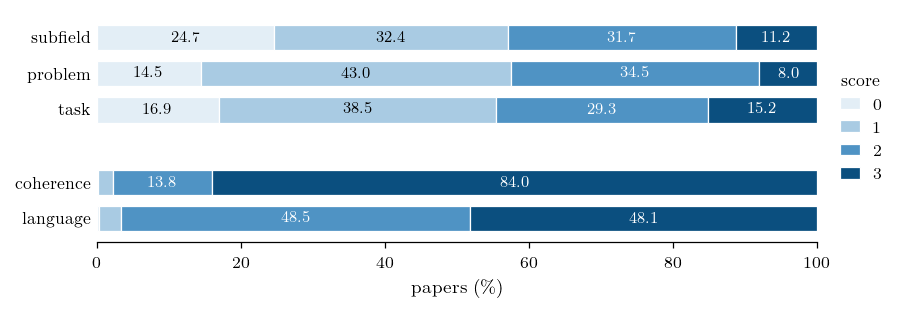

In [3]:
C = ts.COLORS
LEVEL_COLORS = ["#E3EEF6", "#A9CBE3", "#4F93C4", "#0B4F7F"]
rows = ["subfield", "problem", "task", None, "coherence", "language"]   # None: gap between groups
fig, ax = plt.subplots(figsize=(ts.TEXTWIDTH, 50 * ts.MM), layout="constrained")
for y, a in enumerate(rows):
    if a is None:
        continue
    left = 0
    for lvl in range(4):
        w = shares.loc[a, lvl]
        ax.barh(y, w, left=left, height=0.7, color=LEVEL_COLORS[lvl], edgecolor="white", lw=0.6,
                label=str(lvl) if y == 0 else None)
        if w >= 5:
            ax.text(left + w / 2, y, f"{w:.1f}", ha="center", va="center", fontsize=7.5,
                    color="white" if lvl >= 2 else C["black"])
        left += w
ax.set_yticks([y for y, a in enumerate(rows) if a], [a for a in rows if a])
ax.invert_yaxis()
ax.set(xlim=(0, 100), xlabel=ts.tex("papers (%)"))
ax.tick_params(axis="y", length=0)
ax.grid(False)
for s in ("left", "top", "right"):
    ax.spines[s].set_visible(False)
ax.legend(title="score", loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False,
          handlelength=1.2, fontsize=8, title_fontsize=8)
ts.save(fig, "judge_distribution", outdir="../diagrams")
plt.show()